In [1]:
# === Ô GHI LOG  ===
import logging, sys, datetime, warnings
from pathlib import Path
TEN_NOTEBOOK = "01_E0.2_xep_hang_dac_trung_Han"
NGUOI_CHAY   = "Han"

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())  # thư mục gốc repo
thu_muc_log = ROOT / "logs" / "eda_log"
thu_muc_log.mkdir(parents=True, exist_ok=True)
file_log = thu_muc_log / f"{datetime.datetime.now():%Y-%m-%d_%H%M}_{TEN_NOTEBOOK}.log"
tep_log = open(file_log, "a", encoding="utf-8", buffering=1)

if hasattr(sys.stdout, "echo"):                  # chạy trong Jupyter / VS Code: nhờ kernel chép thêm ra file, không thay sys.stdout
    sys.stdout.echo = tep_log
    sys.stderr.echo = tep_log
else:                                            # chạy bằng python thường
    class GhiCaHai:
        def __init__(self, man_hinh, tep): self.man_hinh, self.tep = man_hinh, tep
        def write(self, s): self.man_hinh.write(s); self.tep.write(s); return len(s)
        def flush(self): self.man_hinh.flush(); self.tep.flush()
        def __getattr__(self, ten): return getattr(self.man_hinh, ten)
    sys.stdout = GhiCaHai(sys.__stdout__, tep_log)

logging.basicConfig(stream=sys.stdout, level=logging.INFO, force=True,
                    format="%(asctime)s | %(levelname)s | %(message)s", datefmt="%Y-%m-%d %H:%M:%S")
logging.captureWarnings(True)
log = logging.getLogger(TEN_NOTEBOOK)
log.info(f"Bắt đầu chạy {TEN_NOTEBOOK} – người chạy: {NGUOI_CHAY} – file log: {file_log}")

2026-11-15 21:23:40 | INFO | Bắt đầu chạy 01_E0.2_xep_hang_dac_trung_Han – người chạy: Han – file log: /Users/caongochan/Documents/Challenge_1_House_Prices/logs/eda_log/2026-11-15_2123_01_E0.2_xep_hang_dac_trung_Han.log


# E0.2 – Yếu tố nào quan trọng nhất? (C1 – House Prices)

| | |
|---|---|
| **Tác giả** | Cao Ngọc Hân – Nhóm 11 |
| **Ngày tạo** | 13/11/2026 |
| **Thí nghiệm** | E0.2 – Yếu tố nào quan trọng nhất? |
| **Câu hỏi nghiên cứu** | RQ0: Những đặc trưng nào quyết định giá nhà, và cần bao nhiêu đặc trưng là đủ? |
| **Đọc vào** | `data/raw/train.csv` |
| **Ghi ra** | `figures/eda/c1_E0.2_xep_hang_dac_trung.csv` (dùng ở E0.3, E0.4), 2 hình, `c1_E0.2_tom_tat.txt` |

**Lịch sử sửa**

| Ngày | Người | Nội dung |
|---|---|---|
| 07–08/11/2026 | Hân | Viết trong `01_eda_Han.ipynb` (E0.1–E0.4 chung một notebook) |
| 13/11/2026 | Hân | Tách thành notebook riêng; thêm ô ghi log ra `logs/` |

**Cách chạy:** chạy các notebook EDA theo thứ tự E0.1 → E0.2 → E0.3 → E0.4 (Run All). File log nằm ở `logs/eda_log/`.

In [2]:
import os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.feature_selection import mutual_info_regression
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid", font_scale=1.0)

SEED = 42
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())  # notebook nằm ở notebooks/eda/
DATA = ROOT / "data" / "raw"
FIG = ROOT / "figures" / "eda"
FIG.mkdir(parents=True, exist_ok=True)

# W&B: USE_WANDB là công tắc chung; LOG chọn thí nghiệm nào được log ở lần chạy này.
# Thí nghiệm đã log rồi thì để False để không tạo run trùng.
# Các run W&B của E0.1–E0.4 đã log ngày 07–08/11 (xem evidence/c1_wandb_Han_10-11.png).
# Để USE_WANDB = False khi chạy lại để không tạo run trùng; bật True nếu cần log run mới.
USE_WANDB = False
LOG = {"E0.2": True}
WANDB_ENTITY = "sgu-mayhoc-nhom11"
WANDB_PROJECT = "challenge-1-house-prices"
log.info(f"ROOT: {ROOT}")

2026-11-15 21:23:41 | INFO | ROOT: /Users/caongochan/Documents/Challenge_1_House_Prices


In [3]:
train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
TARGET = "SalePrice"
print("train:", train.shape, "| test:", test.shape)
train.head()

train: (1460, 81) | test: (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
# Chuẩn bị chung (lấy lại từ E0.1): tách đặc trưng, kiểu cột, biến mục tiêu
X = train.drop(columns=["Id", TARGET])
num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
y = train[TARGET]
y_log = np.log1p(y)
log.info(f"{X.shape[1]} đặc trưng ({len(num_cols)} số, {len(cat_cols)} phân loại)")

2026-11-15 21:23:41 | INFO | 79 đặc trưng (36 số, 43 phân loại)


## E0.2 – Yếu tố nào quan trọng nhất?

Bốn thước đo, tất cả so với `log(1 + SalePrice)`:

1. **Tương quan Spearman** (đặc trưng số).
2. **Mutual information** (mọi đặc trưng; đặc trưng phân loại được mã hóa số thứ tự, giá trị thiếu là một nhóm riêng).
3. **Kruskal–Wallis** (đặc trưng phân loại): giá có khác nhau giữa các nhóm không.
4. **SFS đơn biến**: R² 5-fold CV của hồi quy tuyến tính chỉ dùng một đặc trưng (đặc trưng phân loại dùng one-hot).

Mỗi thước đo cho một thứ hạng; xếp hạng cuối là **thứ hạng trung bình** trên các thước đo áp dụng được.

In [5]:
# Chuẩn bị: điền thiếu đơn giản chỉ để phân tích (không phải pipeline mô hình)
Xa = X.copy()
for c in num_cols:
    Xa[c] = Xa[c].fillna(Xa[c].median())
for c in cat_cols:
    Xa[c] = Xa[c].fillna("Missing")
X_codes = Xa.copy()
for c in cat_cols:
    X_codes[c] = X_codes[c].astype("category").cat.codes

# 1. Spearman
spear = Xa[num_cols].apply(lambda s: stats.spearmanr(s, y_log)[0]).abs()

# 2. Mutual information
disc = np.array([c in cat_cols for c in X_codes.columns])
mi = pd.Series(mutual_info_regression(X_codes, y_log, discrete_features=disc, random_state=SEED),
               index=X_codes.columns)

# 3. Kruskal–Wallis
def kruskal_h(c):
    groups = [y_log[Xa[c] == g] for g in Xa[c].unique()]
    groups = [g for g in groups if len(g) > 1]
    return stats.kruskal(*groups)[0] if len(groups) > 1 else np.nan
kw = pd.Series({c: kruskal_h(c) for c in cat_cols})

# 4. SFS đơn biến: R² 5-fold CV với hồi quy tuyến tính trên từng đặc trưng
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
def r2_single(c):
    Z = pd.get_dummies(Xa[c], drop_first=True) if c in cat_cols else Xa[[c]]
    return cross_val_score(LinearRegression(), Z, y_log, cv=kf, scoring="r2").mean()
sfs = pd.Series({c: r2_single(c) for c in X.columns})

kieu = pd.Series({c: ("số" if c in num_cols else "phân loại") for c in X.columns})
scores = pd.DataFrame({"kieu": kieu, "spearman_abs": spear, "mutual_info": mi, "kruskal_H": kw, "R2_don_bien": sfs})
ranks = scores[["spearman_abs", "mutual_info", "kruskal_H", "R2_don_bien"]].rank(ascending=False)
scores["hang_trung_binh"] = ranks.mean(axis=1, skipna=True)
scores = scores.sort_values("hang_trung_binh", kind="stable")
scores.to_csv(FIG / "c1_E0.2_xep_hang_dac_trung.csv")
scores.head(15).round(3)

,kieu,spearman_abs,mutual_info,kruskal_H,R2_don_bien,hang_trung_binh
OverallQual,số,0.810,0.566,NaN,0.661,1.000
Neighborhood,phân loại,NaN,0.528,868.532,0.549,1.667
GrLivArea,số,0.731,0.458,NaN,0.476,2.667
GarageCars,số,0.691,0.374,NaN,0.463,3.667
ExterQual,phân loại,NaN,0.332,683.440,0.452,5.000
GarageArea,số,0.649,0.363,NaN,0.422,6.000
BsmtQual,phân loại,NaN,0.323,674.411,0.447,6.333
KitchenQual,phân loại,NaN,0.330,661.482,0.445,6.667
TotalBsmtSF,số,0.603,0.361,NaN,0.350,7.667
YearBuilt,số,0.653,0.356,NaN,0.337,7.667


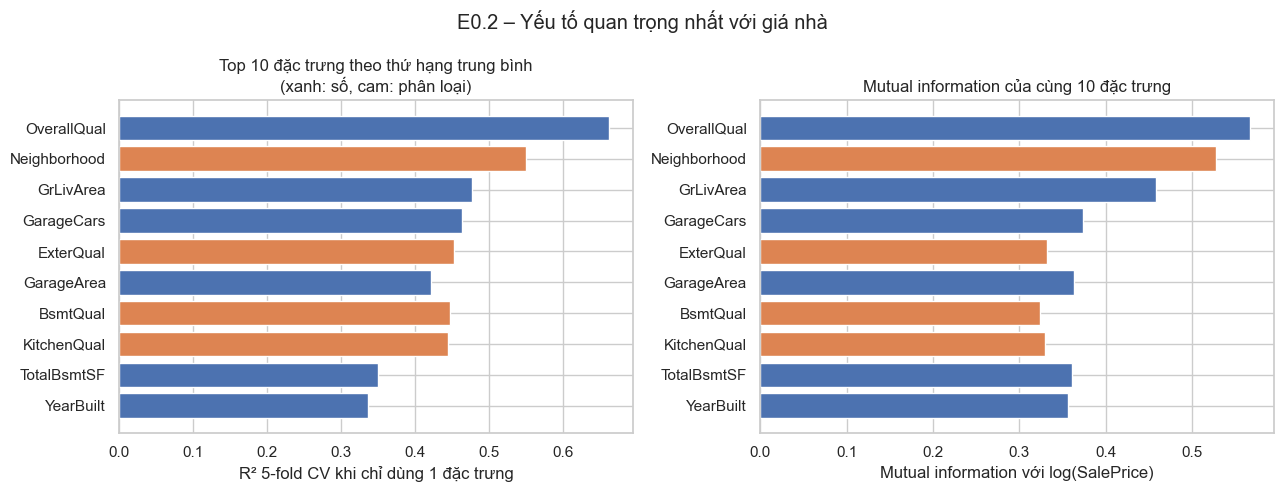

In [6]:
top10 = scores.head(10)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
colors = ["#4C72B0" if k == "số" else "#DD8452" for k in top10["kieu"]]
axes[0].barh(top10.index[::-1], top10["R2_don_bien"][::-1], color=colors[::-1])
axes[0].set_xlabel("R² 5-fold CV khi chỉ dùng 1 đặc trưng")
axes[0].set_title("Top 10 đặc trưng theo thứ hạng trung bình\n(xanh: số, cam: phân loại)")
axes[1].barh(top10.index[::-1], top10["mutual_info"][::-1], color=colors[::-1])
axes[1].set_xlabel("Mutual information với log(SalePrice)")
axes[1].set_title("Mutual information của cùng 10 đặc trưng")
fig.suptitle("E0.2 – Yếu tố quan trọng nhất với giá nhà")
plt.tight_layout(); plt.savefig(FIG / "c1_E0.2_top10_dac_trung.png", dpi=150); plt.show()

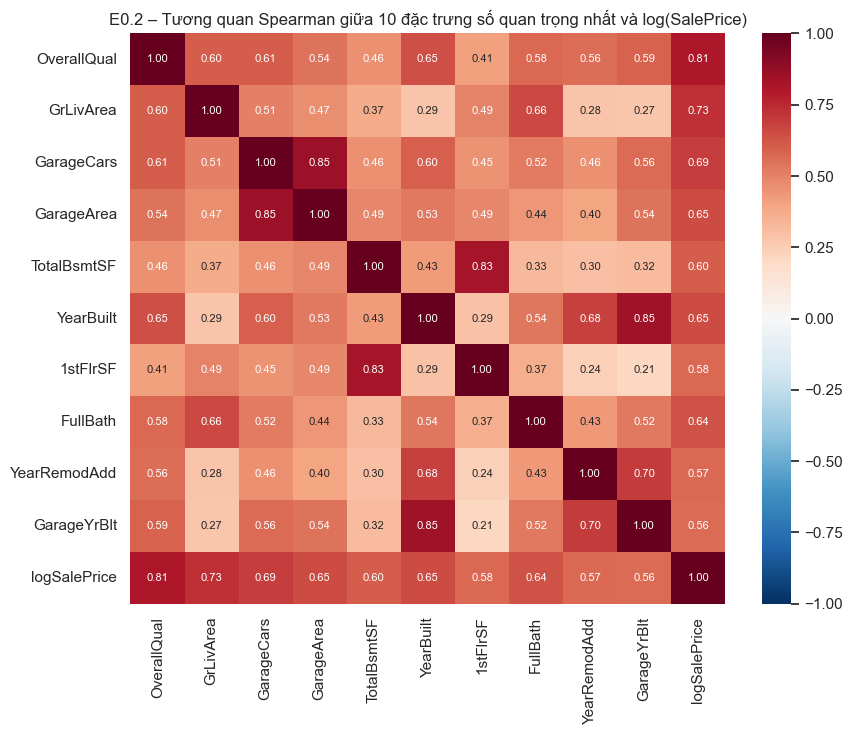

Cặp đặc trưng tương quan > 0.8 (gợi ý cho E0.3): [('GarageCars', 'GarageArea', np.float64(0.85)), ('TotalBsmtSF', '1stFlrSF', np.float64(0.83)), ('YearBuilt', 'GarageYrBlt', np.float64(0.85))]


In [7]:
top_num = [c for c in scores.index if c in num_cols][:10]
corr = pd.concat([Xa[top_num], y_log.rename("logSalePrice")], axis=1).corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, annot_kws={"size": 8})
ax.set_title("E0.2 – Tương quan Spearman giữa 10 đặc trưng số quan trọng nhất và log(SalePrice)")
plt.tight_layout(); plt.savefig(FIG / "c1_E0.2_tuong_quan_top10.png", dpi=150); plt.show()

high_pairs = [(a, b, round(corr.loc[a, b], 2)) for i, a in enumerate(top_num) for b in top_num[i+1:]
              if abs(corr.loc[a, b]) > 0.8]
print("Cặp đặc trưng tương quan > 0.8 (gợi ý cho E0.3):", high_pairs or "không có")

## Tóm tắt E0.2

In [8]:
summary = f"""E0.2 (C1): top 10 đặc trưng theo thứ hạng trung bình của 4 thước đo:
  {', '.join(scores.index[:10])}.
  Đặc trưng đơn lẻ tốt nhất: {scores['R2_don_bien'].idxmax()} (R² CV = {scores['R2_don_bien'].max():.3f})."""
log.info("Tóm tắt " + "E0.2" + ":\n" + summary)
(FIG / "c1_E0.2_tom_tat.txt").write_text(summary, encoding="utf-8")

2026-11-15 21:23:42 | INFO | Tóm tắt E0.2:
E0.2 (C1): top 10 đặc trưng theo thứ hạng trung bình của 4 thước đo:
  OverallQual, Neighborhood, GrLivArea, GarageCars, ExterQual, GarageArea, BsmtQual, KitchenQual, TotalBsmtSF, YearBuilt.
  Đặc trưng đơn lẻ tốt nhất: OverallQual (R² CV = 0.661).


248

## Log lên W&B (minh chứng)

In [9]:
if USE_WANDB:
    import wandb
    def log_run(exp, name, metrics, tables, images, config=None):
        if not LOG.get(exp):
            print(f"Bỏ qua {exp} (LOG = False)"); return
        run = wandb.init(entity=WANDB_ENTITY, project=WANDB_PROJECT, name=name,
                         tags=[exp, "Han", "EDA"], config={"seed": SEED, **(config or {})})
        run.log({**metrics,
                 **{k: wandb.Table(dataframe=v) for k, v in tables.items()},
                 **{f.removesuffix(".png"): wandb.Image(str(FIG / f)) for f in images}})
        run.finish()

    log_run("E0.2", "c1-E0.2-Han-xep-hang-dac-trung",
            {"best_single_feature_r2": float(scores["R2_don_bien"].max())},
            {"bang_xep_hang": scores.round(4).reset_index(names="dac_trung")},
            ["c1_E0.2_top10_dac_trung.png", "c1_E0.2_tuong_quan_top10.png"],
            {"cv_folds": 5, "measures": ["spearman", "mutual_info", "kruskal", "r2_don_bien"]})


## Nhật ký

- 07/11/2026 – Viết xếp hạng đặc trưng (E0.2) lần đầu trong notebook `01_eda_TV1.ipynb`. Commit `68a3cbe`.
- 07/11/2026 – Đổi tên notebook `01_eda_TV1.ipynb` thành `01_eda_Han.ipynb`. Commit `7496f72`.
- 13/11/2026 – Tách E0.2 ra thành notebook riêng `01_E0.2_xep_hang_dac_trung_Han.ipynb`, thêm ô ghi log. Chạy lại, số khớp bản 08/11. Commit `2c629a8`.